## Q1

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_bvp

In [ ]:
def rhs(s, y):
    f, g = y
    return np.vstack([g, f**3 - f])

def bc(ya, yb):
    # f = 0 at both walls
    return np.array([ya[0], yb[0]])

def solve_box(L, n=401):
    s = np.linspace(-L/2, L/2, n)
    # nonzero initial guess (f = 0 is also a solution, so avoid starting there)
    f0 = np.tanh((s + L/2)/np.sqrt(2)) * np.tanh((L/2 - s)/np.sqrt(2))
    g0 = np.gradient(f0, s)
    sol = solve_bvp(rhs, bc, s, np.vstack([f0, g0]), tol=1e-8, max_nodes=100000)
    assert sol.success, sol.message
    return sol

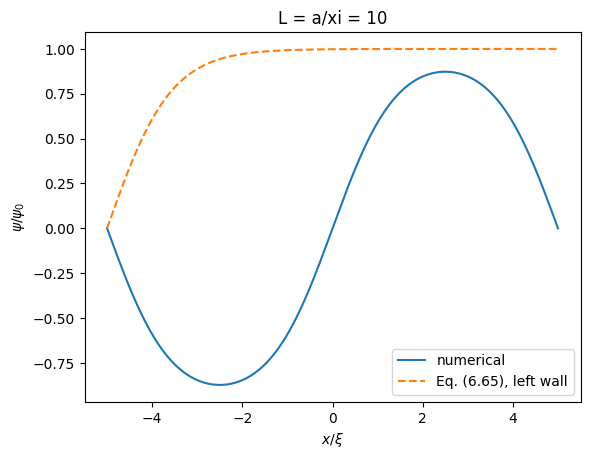

f at centre = 8.585586056133589e-17


In [10]:
L = 10
sol = solve_box(L)
s = np.linspace(-L/2, L/2, 1000)
f = sol.sol(s)[0]

plt.plot(s, f, label='numerical')
plt.plot(s, np.tanh((s + L/2)/np.sqrt(2)), '--', label=r'Eq. (6.65), left wall')
plt.xlabel(r'$x/\xi$')
plt.ylabel(r'$\psi/\psi_0$')
plt.title(f'L = a/xi = {L}')
plt.legend()
plt.show()

print('f at centre =', sol.sol(0)[0])

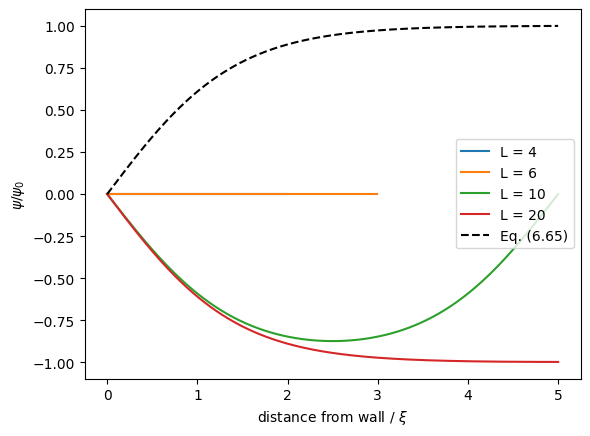

In [11]:
d = np.linspace(0, 5, 300)   # distance from the left wall, in units of xi
for L in [4, 6, 10, 20]:
    sol = solve_box(L)
    dd = d[d <= L/2]
    plt.plot(dd, sol.sol(dd - L/2)[0], label=f'L = {L}')
plt.plot(d, np.tanh(d/np.sqrt(2)), 'k--', label='Eq. (6.65)')
plt.xlabel(r'distance from wall / $\xi$')
plt.ylabel(r'$\psi/\psi_0$')
plt.legend()
plt.show()

## Q2

In [ ]:
H_BAR = 1.054571817e-34  # Reduced Planck's constant in SI units
A_0 = 5.29177210903e-11  # Bohr radius in meters
A_U = 1.66054e-27  # Atomic mass unit in kg
K_B = 1.380649e-23  # Boltzmann constant in SI units

N = 1e5  # Number of atoms
m = 87 * A_U  # Mass of Rb-87 atom in kg
a = 100 * A_0  # Scattering length in meters
w = 2 * np.pi * 200  # Trap frequency in rad/s
a_osc = np.sqrt(H_BAR / (m * w))  # Oscillator length in meters
fraction = N * a / a_osc

print('N * a / a_osc =', fraction)

mu = (15**(2/5) / 2) * (fraction**(2/5)) * H_BAR * w # Chemical potential in Joules
print('Chemical potential mu =', mu, 'J =', mu * 1e6 / K_B, 'uK / k_B')

R = (2 * mu / (m * w**2))**0.5  # Thomas-Fermi radius in meters
print('Thomas-Fermi radius R =', R, 'm')

E = (5/7) * mu * N  # Total energy in Joules
print('Total energy E =', E, 'J =', E * 1e3 / K_B, 'mK / k_B')

xi = (H_BAR**2 / (2 * m * mu))**0.5  # Healing length in meters
print('Healing length xi =', xi, 'm =', xi / A_0, 'a0 =', xi / R, 'R')

N * a / a_osc = 694.3081795787895
Chemical potential mu = 2.6811026718866847e-30 J = 0.1941914760295111 uK / k_B
Thomas-Fermi radius R = 4.848166869492794e-06 m
Total energy E = 1.9150733370619177e-25 J = 13.87081971639365 mK / k_B
Healing length xi = 1.198174694812273e-07 m = 2264.2220226522613 a0 = 0.024713973901183472 R


## Q3